(writing-your-own-base-learner-with-buser)=
# Custom base learners with `buser`

`buser` takes a design matrix $X$ and a penalty matrix $K$ and turns them into a
base learner. At each boosting step the learner fits the current residual by
penalised least squares,

$$
\hat\beta = (X^\top W X + \lambda K)^{-1} X^\top W u,
$$

and contributes $X\hat\beta$, shrunk by the learning rate. The columns of $X$ determine the functions the learner can fit. The quadratic
penalty $\beta^\top K\beta$ determines which coefficient patterns are shrunk
most strongly. The smoothing parameter $\lambda$ is chosen to give the
requested degrees of freedom.

Built-in penalised least-squares learners such as `bbs` and `bols` construct
$X$ and $K$ from the formula. With `buser`, you supply those matrices yourself.

This case shows how to supply a design matrix and penalty to `buser`, then
construct a matching design for predictions on new rows. Reproducing a built-in spline comes first; periodic extrapolation and
learner fairness follow as extensions.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | how to write a base learner by supplying a design and a penalty matrix |
| **Observed response** | a simulated continuous outcome |
| **Estimand** | the fitted effect of the custom learner, checked against the known generating function |
| **Units** | simulated, arbitrary scale |
| **Sampling unit** | one simulated observation |
| **Dependence** | independent by construction |
| **Split / resampling unit** | the observation |
| **Tuning** | fixed `mstop`; the study is about the learner, not the stopping point |
| **Uncertainty** | not quantified — correctness is checked against the known truth |
| **Claim type** | methodological |
:::


In [1]:
import warnings

import numpy as np
import polars as pl
import altair as alt

import mboostrs as mb
from sklearn.metrics import r2_score

warnings.filterwarnings("ignore")
rng = np.random.default_rng(0)

## Reproducing `bbs` with `buser`

`learner_design("bbs(x, df=4)", data)` returns the fitted design and
penalty used by that learner: a cubic B-spline basis on 20 interior knots, 24 columns, and
a second-difference penalty. Passing those matrices to `buser` reproduces the learner used by `bbs`, allowing
a direct comparison of their fitted predictions.

In [2]:
n = 300
smooth = {"x": np.sort(rng.uniform(0, 10, n))}
smooth["y"] = np.sin(smooth["x"]) + rng.normal(0, 0.3, n)

basis = mb.learner_design("bbs(x, df=4)", smooth)
X, K = basis.design, basis.penalty
print(f"design {X.shape}, penalty {K.shape}")
print(f"penalty rank {np.linalg.matrix_rank(K)} of {K.shape[0]}: a null space of "
      f"dimension {K.shape[0] - np.linalg.matrix_rank(K)}, the shapes it does not "
      f"penalise at all")

formula_fit = mb.gamboost("y ~ bbs(x, df=4)", data=smooth, family=mb.Gaussian(),
                      control=mb.boost_control(200, 0.1))
by_hand = mb.gamboost("y ~ buser(x, X=DX, K=DK, df=4)", data=smooth,
                      family=mb.Gaussian(), env={"DX": X, "DK": K},
                      control=mb.boost_control(200, 0.1))
a = np.asarray(formula_fit.predict()).ravel()
b = np.asarray(by_hand.predict()).ravel()
print(f"\nlargest difference between the two fits: {np.abs(a - b).max():.3e}")

design (300, 24), penalty (24, 24)
penalty rank 22 of 24: a null space of dimension 2, the shapes it does not penalise at all

largest difference between the two fits: 0.000e+00


The two fits agree to the last bit. The design and penalty matrices are passed
through the `env=` argument, which is how a formula refers to matrices that are
not columns of the data.

A second-difference penalty leaves a two-dimensional null space: constants and
straight lines have zero penalty. As the penalty increases, the curve shrinks
toward a straight line. A different $K$ can leave different functions
unpenalised.

(example-a-fourier-basis-for-seasonal-data)=
## Fourier basis for seasonal data

A Fourier basis represents a periodic effect using sine and cosine terms.
Supplying it to `buser` makes the fitted contribution repeat at the specified
period, including beyond the observed range.

Twenty-four months of a seasonal series are observed and the next twelve are
predicted. The period is known to be 12. A Fourier basis with three harmonics
encodes that; a P-spline does not know the series repeats.

In [3]:
t_all = np.arange(0, 36, 0.25)
# Fix the random draw so the resampling result is reproducible.
truth = 2 * np.sin(2 * np.pi * t_all / 12) + 0.6 * np.cos(4 * np.pi * t_all / 12) + 0.04 * t_all

observed = t_all < 24

season = {"t": t_all[observed],
          "y": (truth + np.random.default_rng(1).normal(0, 0.35, len(t_all)))[observed]}

ahead = t_all[~observed]

def fourier(t, period=12, harmonics=3):
    columns = [np.ones_like(t)]
    for k in range(1, harmonics + 1):
        columns += [np.sin(2 * np.pi * k * t / period),
                    np.cos(2 * np.pi * k * t / period)]
    return np.column_stack(columns)

F_fit, F_ahead = fourier(season["t"]), fourier(ahead)

F_pen = np.eye(F_fit.shape[1])

F_pen[0, 0] = 0.0          # the constant column is not shrunk

spline = mb.gamboost("y ~ bbs(t, df=4)", data=season, family=mb.Gaussian(),
                     control=mb.boost_control(400, 0.1))

periodic = mb.gamboost("y ~ bols(t) + buser(t, X=FX, K=FK, df=4)", data=season,
                       family=mb.Gaussian(), env={"FX": F_fit, "FK": F_pen},
                       control=mb.boost_control(400, 0.1))

p_spline = np.asarray(spline.predict(newdata={"t": ahead})).ravel()


In [4]:
p_periodic = np.asarray(periodic.predict(newdata={"t": ahead},
                                         buser_newdata={"t": F_ahead})).ravel()

display(pl.DataFrame({
    "learner": ["bbs(t, df=4)", "buser, Fourier basis"],
    "R2 on months 0-24 (fitted)": [
        round(r2_score(truth[observed], np.asarray(spline.predict()).ravel()), 3),
        round(r2_score(truth[observed], np.asarray(periodic.predict()).ravel()), 3)],
    "R2 on months 24-36 (never seen)": [
        round(r2_score(truth[~observed], p_spline), 3),
        round(r2_score(truth[~observed], p_periodic), 3)],
}))


learner,R2 on months 0-24 (fitted),R2 on months 24-36 (never seen)
str,f64,f64
"""bbs(t, df=4)""",0.925,-15.965
"""buser, Fourier basis""",0.999,0.998


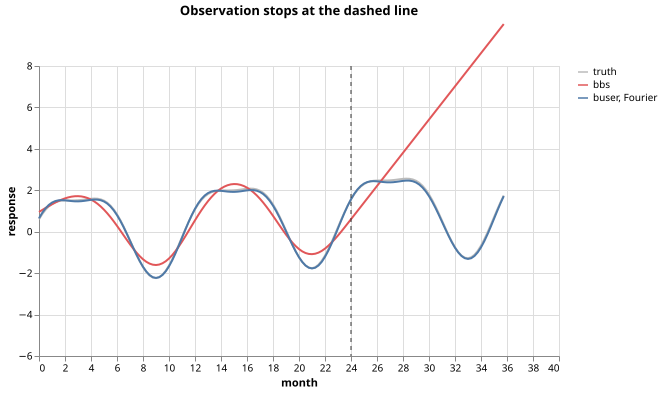

In [5]:
grid_all = fourier(t_all)
curves = pl.concat([
    pl.DataFrame({"t": t_all, "value": truth, "series": ["truth"] * len(t_all)}),
    pl.DataFrame({"t": t_all,
                  "value": np.asarray(spline.predict(newdata={"t": t_all})).ravel(),
                  "series": ["bbs"] * len(t_all)}),
    pl.DataFrame({"t": t_all,
                  "value": np.asarray(periodic.predict(
                      newdata={"t": t_all}, buser_newdata={"t": grid_all})).ravel(),
                  "series": ["buser, Fourier"] * len(t_all)}),
])
palette = alt.Color("series:N", title=None,
                    scale=alt.Scale(domain=["truth", "bbs", "buser, Fourier"],
                                    range=["#bbbbbb", "#e15759", "#4e79a7"]))
line = alt.Chart(curves).mark_line(strokeWidth=2).encode(
    x=alt.X("t:Q", title="month"),
    y=alt.Y("value:Q", title="response", scale=alt.Scale(domain=[-6, 8])),
    color=palette)
edge = alt.Chart(pl.DataFrame({"t": [24.0]})).mark_rule(
    strokeDash=[4, 4], color="#333333").encode(x="t:Q")
(line + edge).properties(width=520, height=290,
    title="Observation stops at the dashed line")

Inside the observed range both fits are fine. Past it the P-spline continues at
the slope it had at its last knot, because that is what a P-spline does beyond
its boundary, and the fit runs away from a signal that is in fact still
oscillating. The Fourier contribution repeats every twelve months because every column of
its design matrix has that period. This extrapolation depends on the assumed
period remaining appropriate for the unobserved months.

(the-penalty-in-a-gap-in-the-data)=
## Penalties in an unobserved gap

$X$ and $K$ do different jobs, and the difference is easiest to see in a gap.
The data below cover 0 to 4 and 7 to 10, with nothing in between. Both fits use
the same B-spline design and the same `df=4`; only $K$ differs.

In [6]:
gapped = {"x": np.sort(np.concatenate([rng.uniform(0, 4, 150),
                                       rng.uniform(7, 10, 150)]))}
gapped["y"] = 0.8 * gapped["x"] + rng.normal(0, 0.3, len(gapped["x"]))
gap_basis = mb.learner_design("bbs(x, df=4)", gapped)
Xg, K_diff = gap_basis.design, gap_basis.penalty
line_grid = {"x": np.linspace(0, 10, 101)}
X_grid = gap_basis.transform(line_grid)
# Fix the random draw so the resampling result is reproducible.
rows, shapes = [], []
for label, penalty in (("second difference", K_diff),
                       ("identity (ridge)", np.eye(Xg.shape[1]))):
    fit = mb.gamboost("y ~ buser(x, X=DX, K=DK, df=4)", data=gapped,
                      family=mb.Gaussian(), env={"DX": Xg, "DK": penalty},
                      control=mb.boost_control(600, 0.1))
    curve = np.asarray(fit.predict(newdata=line_grid,
                                   buser_newdata={"x": X_grid})).ravel()
    inside = (line_grid["x"] >= 4) & (line_grid["x"] <= 7)
    rows.append({"penalty": label,
                 "fitted at x=4": round(float(curve[40]), 2),
                 "fitted at x=5.5": round(float(curve[55]), 2),
                 "fitted at x=7": round(float(curve[70]), 2),
                 "curvature across the gap":
                     round(float(np.abs(np.diff(curve[inside], 2)).mean()), 5)})
    shapes.append(pl.DataFrame({"x": line_grid["x"], "fitted": curve,
                                "penalty": [label] * 101}))
display(pl.DataFrame(rows))


penalty,fitted at x=4,fitted at x=5.5,fitted at x=7,curvature across the gap
str,f64,f64,f64,f64
"""second difference""",3.19,4.4,5.6,0.00008
"""identity (ridge)""",3.23,4.2,5.64,0.01457


A second-difference penalty shrinks changes between adjacent coefficient
differences. In the unobserved gap, this favours an approximately straight
continuation: the curvature across
the gap is 0.00008. A ridge penalty shrinks coefficient magnitudes without penalising differences
between neighbours, and the resulting curvature is roughly 180 times as large
(0.0146) in a region containing no observations at all.

Both learners use `df=4`, but this scalar does not determine the fitted shape.
The penalty matrix determines which coefficient patterns are shrunk at that
degree of freedom.

## Prediction on new data: `buser_newdata`

`bbs` remembers its knots and rebuilds its own design for new rows. `buser`
cannot, because it never saw a variable — only a matrix. Every prediction on new
data needs the matching design supplied through `buser_newdata`.

In [7]:
try:
    periodic.predict(newdata={"t": ahead})
except ValueError as err:
    print(f"ValueError: {err}")

ValueError: predict(newdata=...) with Buser learners requires buser_newdata: dict mapping Buser name -> X_new matrix (n_new, p). Pass the new design matrices for each Buser learner.


Omitting `buser_newdata` raises an error. A supplied matrix can have the
expected dimensions and still produce incorrect predictions if its columns
use different basis functions from those used during fitting.

Below, a model is fitted on `x` over 0 to 10 and asked to predict on rows
covering only 2 to 6. The correct design evaluates the *fitted* basis at the new
rows. The mistake is to rebuild the basis from the new data, which places its
knots over 2 to 6 instead: the matrix has the right shape, the call succeeds,
and the coefficients now multiply the wrong columns.

In [8]:
train = {"x": np.sort(rng.uniform(0, 10, 240))}
train["y"] = np.sin(train["x"]) + rng.normal(0, 0.3, 240)
later = {"x": np.sort(rng.uniform(2, 6, 120))}
later_truth = np.sin(later["x"])

train_basis = mb.learner_design("bbs(x, df=4)", train)
X_train, K_train = train_basis.design, train_basis.penalty
fitted = mb.gamboost("y ~ buser(x, X=DX, K=DK, df=4)", data=train,
                     family=mb.Gaussian(), env={"DX": X_train, "DK": K_train},
                     control=mb.boost_control(400, 0.1))

correct = train_basis.transform(later)
refitted = mb.learner_design("bbs(x, df=4)", later).design
display(pl.DataFrame([
    {"design for the new rows": "the fitted basis, evaluated at the new x",
     "shape": str(correct.shape),
     "R2": round(r2_score(later_truth, np.asarray(fitted.predict(
         newdata=later, buser_newdata={"x": correct})).ravel()), 3)},
    {"design for the new rows": "a basis refitted on the new x",
     "shape": str(refitted.shape),
     "R2": round(r2_score(later_truth, np.asarray(fitted.predict(
         newdata=later, buser_newdata={"x": refitted})).ravel()), 3)},
]))

design for the new rows,shape,R2
str,str,f64
"""the fitted basis, evaluated at…","""(120, 24)""",0.996
"""a basis refitted on the new x""","""(120, 24)""",-1.226


Rebuilding the knots changes R2 from 0.996 to -1.226, worse than predicting
the mean, even though the matrix dimensions pass validation. Keep the fitted
basis alongside a `buser` model and evaluate that basis on every new row.

## Extension: degrees of freedom and selection

Boosting selects one base learner per step: the one that best fits the current
residual. A learner with more degrees of freedom fits any residual better,
including a residual that is pure noise, so it wins steps for reasons that have
nothing to do with signal.

The model below contains `bbs(x, df=4)` and a `buser` carrying *the same basis
matrix*, so at `df=4` the two learners are the same learner. A third term,
`bbs(z, df=4)`, is attached to pure noise and should ideally never be selected.

In [9]:
comp = {"x": np.sort(rng.uniform(0, 10, 400)), "z": rng.normal(0, 1, 400)}
comp["y"] = np.sin(comp["x"]) + rng.normal(0, 0.4, 400)
comp["xb"] = np.zeros(400)          # placeholder column that names the buser term
comp_basis = mb.learner_design("bbs(x, df=4)", comp)
Xc, Kc = comp_basis.design, comp_basis.penalty

import collections
rows = []
for df in (2, 4, 8, 16, 24):
    fit = mb.gamboost(
        f"y ~ bbs(x, df=4) + buser(xb, X=DX, K=DK, df={df}) + bbs(z, df=4)",
        data=comp, family=mb.Gaussian(), env={"DX": Xc, "DK": Kc},
        control=mb.boost_control(400, 0.1))
    picked = collections.Counter(fit.selected)
    rows.append({"buser df": df, "steps on bbs(x)": picked.get("x", 0),
                 "steps on buser": picked.get("xb", 0),
                 "steps on the noise variable": picked.get("z", 0)})
display(pl.DataFrame(rows))

buser df,steps on bbs(x),steps on buser,steps on the noise variable
i64,i64,i64,i64
2,337,0,63
4,337,0,63
8,0,311,89
16,0,268,132
24,0,57,343


At `df=2` the `buser` term is less flexible than `bbs(x)` and is never chosen. At
`df=4`, where the two are identical, the steps split. From `df=8` upward the
`buser` term takes every step that would have gone to `bbs(x)` — not because it
fits `x` better, since it is the same basis, but because it is allowed to move
further per step.

The last column reports updates to `bbs(z)`. Steps spent on this pure-noise
variable rise from 63 to 343 as the `buser` term's degrees of freedom grow. A
learner that absorbs the signal in fewer steps leaves more of the remaining updates available
for fitting residual noise.

Choose degrees of freedom comparable to the other candidate learners so that
flexibility alone does not favour `buser` at each update. Supplying $X$ and $K$
does not select that value; set `df` explicitly for the intended comparison.

## Limitations of `buser`

**It does not know what variable it is looking at.** The name in
`buser(name, ...)` is a column of the data used only as a label; the fit comes
entirely from `X=`. Two learners can end up sharing a name, and then
`model.selected` cannot tell them apart — which is why the comparison above
introduced an `xb` placeholder column. Give every `buser` term a name no other
term uses.

**It does not build the design.** Knots, centring, standardisation, handling of
a category never seen in training: all of it is the caller's, at fit time and
again at prediction time.

**It materialises the design densely.** $X$ is stored as a dense $n \times p$
array. That is 0.11 GB for 28 designs of 144 columns at $n=3750$, and 0.84 GB
for 210 of them, which is the practical ceiling on how many `buser` terms a
formula can hold.

**It gives no help interpreting the result.** A fitted `bbs` term has a partial
effect that can be plotted against its variable. A fitted `buser` term is a
coefficient vector against columns whose meaning only you know.

To reuse a custom learner, retain its basis construction, penalty matrix and
training-time settings alongside the fitted model. Those settings are needed
to build matching design columns for new observations.